# Laborator 5, Exercițiul 1
## Modele Markov ascunse

## a) Definirea modelului cu `hmmlearn`

Notele sunt categorii discrete, deci folosim `CategoricalHMM`. Setăm manual cele trei obiecte ale HMM-ului, $\pi$ (`startprob_`), $A$ (`transmat_`) și $B$ (`emissionprob_`), folosind `init_params=""`, ca biblioteca să nu le reinițializeze aleator.

In [8]:
import numpy as np
from hmmlearn import hmm

stari = ["dificil", "mediu", "usor"]
note = ["FB", "B", "S", "NS"]

model = hmm.CategoricalHMM(n_components=3, init_params="")

# Probabilitatile initiale: dificultatea primului test, uniforma
model.startprob_ = np.array([1/3, 1/3, 1/3])

# Matricea de tranzitie A[i, j] = P(stare_urmatoare=j | stare_curenta=i)
model.transmat_ = np.array([
    [0.0,  0.5,  0.5 ],   # din dificil -> mediu / usor
    [0.5,  0.25, 0.25],   # din mediu   -> dificil / mediu / usor
    [0.5,  0.25, 0.25],   # din usor    -> dificil / mediu / usor
])

# Matricea de emisie B[i, k] = P(nota=k | dificultate=i), ordine FB, B, S, NS
model.emissionprob_ = np.array([
    [0.1,  0.2,  0.4, 0.3],   # dificil
    [0.15, 0.25, 0.5, 0.1],   # mediu
    [0.2,  0.3,  0.4, 0.1],   # usor
])

print("sume linii tranzitie:", model.transmat_.sum(axis=1))
print("sume linii emisie:   ", model.emissionprob_.sum(axis=1))

sume linii tranzitie: [1. 1. 1.]
sume linii emisie:    [1. 1. 1.]


### Diagrama de stare

Construim graful tranzițiilor direct din matricea $A$ (o muchie pentru fiecare $a_{ij} > 0$, etichetată cu probabilitatea).

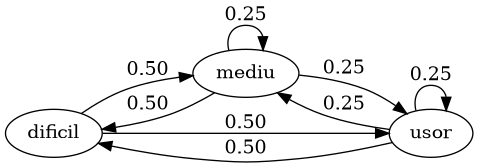

In [9]:
import networkx as nx
from IPython.display import Image

# Construim graful direct din matricea de tranzitie: un nod per stare,
# o muchie pentru fiecare probabilitate nenula.
graf = nx.DiGraph()
for i, sursa in enumerate(stari):
    for j, destinatie in enumerate(stari):
        probabilitate = model.transmat_[i, j]
        if probabilitate > 0:
            graf.add_edge(sursa, destinatie, label=f"{probabilitate:.2f}")

diagrama = nx.nx_pydot.to_pydot(graf)
diagrama.set_rankdir("LR")
Image(diagrama.create_png())

## b) Cea mai probabilă secvență de dificultăți

Se cere secvența de stări ascunse cea mai probabilă dată fiind secvența observată:

$$s_{1:T}^{*} = \arg\max_{s_{1:T}} P(s_{1:T} \mid o_{1:T}).$$

Rezolvarea se face cu algoritmul **Viterbi**, care maximizează probabilitatea unui singur traseu.

În `hmmlearn`, `model.decode(..., algorithm="viterbi")` întoarce drumul optim $s_{1:T}^{*}$ și $\log P(s_{1:T}^{*}, o_{1:T})$.

In [10]:
# Secventa observata de note
secventa = ["FB", "FB", "S", "B", "B", "S", "B", "B", "NS", "B", "B", "S"]

# hmmlearn cere observatiile codate ca intregi, intr-o coloana
X = np.array([[note.index(o)] for o in secventa])

logprob, drum = model.decode(X, algorithm="viterbi")
dificultati = [stari[i] for i in drum]

for n, d in zip(secventa, dificultati):
    print(f"{n:>3}  ->  {d}")
print()
print("log-probabilitate:", logprob)
print("probabilitate:    ", np.exp(logprob))

 FB  ->  usor
 FB  ->  usor
  S  ->  dificil
  B  ->  usor
  B  ->  dificil
  S  ->  mediu
  B  ->  dificil
  B  ->  usor
 NS  ->  dificil
  B  ->  usor
  B  ->  dificil
  S  ->  mediu

log-probabilitate: -24.582044327855733
probabilitate:     2.109375000000024e-11


Secvența cea mai probabilă are probabilitatea $P(s_{1:T}^{*}, o_{1:T}) \approx 2.11 \times 10^{-11}$ (adică $\log P \approx -24.58$).